In [ ]:
import numpy as np
import pyboat as pb
import matplotlib.pyplot as plt
import os
import pickle


def generate_test_signals(
    num_signals: int = 100,
    signal_length: int = 1000,
    time_end: float = 100.0,
    noise_std: float = 0.5,
) -> tuple[np.ndarray, np.ndarray]:
    """
    Generate test signals with varying frequencies and trends.

    Returns:
    - t: time vector (shape: [signal_length])
    - signals: generated noisy signals (shape: [signal_length, num_signals])
    """
    np.random.seed(42)
    t = np.linspace(0, time_end, signal_length)
    freqs = np.linspace(1 / 30, 1 / 5, num_signals)  # period between 5 and 30
    signals = []

    for f in freqs:
        trend = 0.1 * t
        noise = np.random.randn(len(t)) * noise_std
        signal = np.sin(2 * np.pi * f * t) + trend + noise
        signals.append(signal)

    signals = np.array(signals).T  # Transpose to shape [Time, ROIs]
    return t, signals


def apply_pyboat_detrending(
    signals: np.ndarray, t: np.ndarray, cutoff_periods: list[float]
) -> dict[str, np.ndarray]:
    """
    Apply pyBOAT sinc detrending for multiple cutoff periods.

    Input signals are expected in [Time, ROIs] format.

    Returns:
    - Dictionary: {cutoff_period_str: detrended_signals} in [Time, ROIs]
    """
    dt = t[1] - t[0]
    outputs = {}
    for T_c in cutoff_periods:
        detrended = np.empty_like(signals)
        for i in range(signals.shape[1]):  # Loop over ROIs
            detrended[:, i] = signals[:, i] - pb.sinc_smooth(signals[:, i], T_c, dt)
        outputs[f"T_c={T_c}"] = detrended
    return outputs


def save_dataset(
    input_signals: np.ndarray,
    t: np.ndarray,
    detrended_signals_dict: dict[str, np.ndarray],
    out_dir: str = "detrend_test_data",
):
    """
    Save the input signals, time vector, and pyBOAT reference outputs to disk.
    """
    os.makedirs(out_dir, exist_ok=True)

    np.save(os.path.join(out_dir, "time.npy"), t)
    np.save(os.path.join(out_dir, "input_signals.npy"), input_signals)

    for key, output in detrended_signals_dict.items():
        tag = key.replace("=", "_")
        np.save(os.path.join(out_dir, f"pyboat_detrended_{tag}.npy"), output)

    metadata = {
        "cutoff_periods": list(detrended_signals_dict.keys()),
        "num_signals": input_signals.shape[1],  # ROIs
        "signal_length": input_signals.shape[0],  # Time
    }
    with open(os.path.join(out_dir, "metadata.pkl"), "wb") as f:
        pickle.dump(metadata, f)


# ---- Run everything ----

t, input_signals = generate_test_signals()

cutoff_periods = [100, 200, 300, 400, 500]
pyboat_outputs = apply_pyboat_detrending(input_signals, t, cutoff_periods)

save_dataset(input_signals, t, pyboat_outputs)

print("Test dataset saved to folder: 'detrend_test_data'")

✅ Test dataset saved to folder: 'detrend_test_data'


In [80]:
import numpy as np
from math import pi
from scipy.signal import fftconvolve


def blackman_sinc_filter_kernel(kernel_window: int, cutoff_freq: float) -> list[float]:
    """Generates a Blackman windowed sinc filter kernel

    :param kernel_window: window size for the kernel, must be even
    :type kernel_window: int
    :param cutoff_freq: cut-off frequency, oscillations of lower frequencies will be blocked
    :type cutoff_freq: float
    :return: returns the filter kernel as a list of floats
    :rtype: list

    See the pyBOAT paper (https://www.biorxiv.org/content/10.1101/2020.04.29.067744v2) and Chapter 16 of the The Scientist and Engineer's Guide to Digital Signal Processing (https://www.dspguide.com/ch16/1.htm) for more details.
    """
    if kernel_window % 2 != 0:
        raise ValueError("Filter kernel window must be even")
    kernel_values = []

    midpoint = kernel_window / 2
    for n in range(kernel_window + 1):
        if n == midpoint:
            val = 2 * pi * cutoff_freq
        else:
            val = np.sin(2 * pi * cutoff_freq * (n - midpoint)) / (n - midpoint)
        # Apply Blackman window
        val *= (
            0.42
            - 0.5 * np.cos(2 * pi * n / kernel_window)
            + 0.08 * np.cos(4 * pi * n / kernel_window)
        )
        kernel_values.append(val)

    kernel = np.array(kernel_values)
    kernel /= np.sum(kernel)
    return kernel


def convolve_signals_with_kernel(
    signals: np.ndarray, filter_kernel: list
) -> np.ndarray:
    """Convolve a 2D array of signals with a filter kernel using FFT convolution.

    :param signals: 2D numpy array of shape (T x n_rois)
    :type signals: np.ndarray
    :param filter_kernel: kernel to convolve with, must be odd length
    :type filter_kernel: list
    :raises ValueError: raises a ValueError if the filter kernel length is not odd
    :return: 2D numpy array of convolved signals in the shape (T x n_rois)
    :rtype: np.ndarray
    """
    kernel_length = len(filter_kernel)
    if kernel_length % 2 == 0:
        raise ValueError("Filter kernel length must be odd")

    # Convert to 1D array if needed
    filter_kernel = np.asarray(filter_kernel).flatten()

    # Pad signals along time axis (axis=0)
    left_padding = signals[kernel_length - 1 : 0 : -1, :]
    right_padding = signals[-2 : -kernel_length - 1 : -1, :]
    padded_signals = np.concatenate([left_padding, signals, right_padding], axis=0)

    # Apply convolution along axis=0 (time)
    convolved = fftconvolve(
        padded_signals, filter_kernel[:, None], mode="valid", axes=0
    )

    # Extract center portion to match input shape
    start = (kernel_length - 1) // 2
    end = start + signals.shape[0]
    result = convolved[start:end, :]

    return result


def detrend_with_sinc_filter(
    signals: np.ndarray, cutoff_period: float, sampling_interval: float
) -> np.ndarray:
    """Applies a Blackman-windowd sinc filter to a 2D array of signals to detrend them.

    Frequencies of lower frequencies than the cutoff frequency will be blocked, while higher frequencies will pass through unaffected.

    :param signals: 2D numpy array of shape (T x n_rois)
    :type signals: np.ndarray
    :param cutoff_period: cutoff period in time units, lower frequencies will be blocked
    :type cutoff_period: float
    :param sampling_interval: sampling interval in time units of the signals
    :type sampling_interval: float
    :return: returns the detrended signals as a 2D numpy array of shape (num_signals, signal_length)
    :rtype: np.ndarray
    """
    signal_length, _ = signals.shape
    print(signal_length)

    kernel_window = signal_length - 1
    if kernel_window % 2 != 0:
        kernel_window -= 1  # Make kernel window even

    cutoff_frequency = (
        sampling_interval / cutoff_period
    )  # Cutoff freq in sampling units

    filter_kernel = blackman_sinc_filter_kernel(kernel_window, cutoff_frequency)
    smoothed_signals = convolve_signals_with_kernel(signals, filter_kernel)

    detrended_signals = signals - smoothed_signals
    return detrended_signals

In [ ]:
print(input_signals.shape)

outputs_custom_impl = {}
dt = t[1] - t[0]
for T_c in cutoff_periods:
    detrended = detrend_with_sinc_filter(input_signals, T_c, dt)
    outputs_custom_impl[f"T_c={T_c}"] = detrended

print(input_signals.shape)

(1000, 100)
1000
1000
1000
1000
1000
(1000, 100)


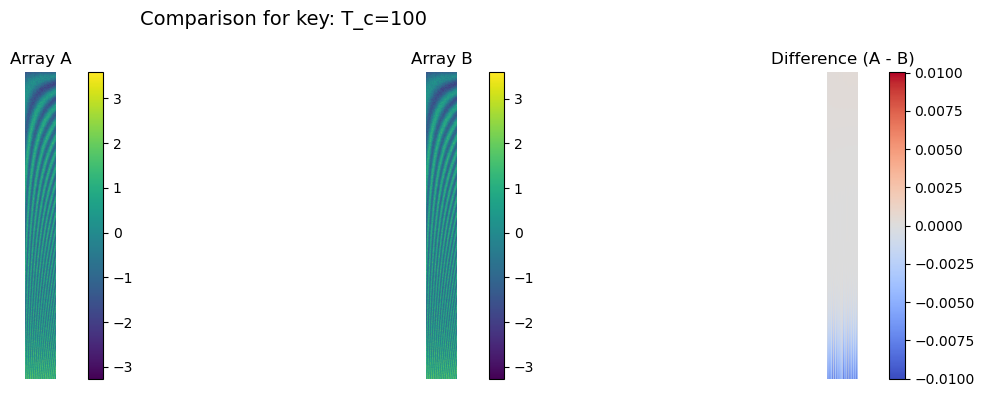

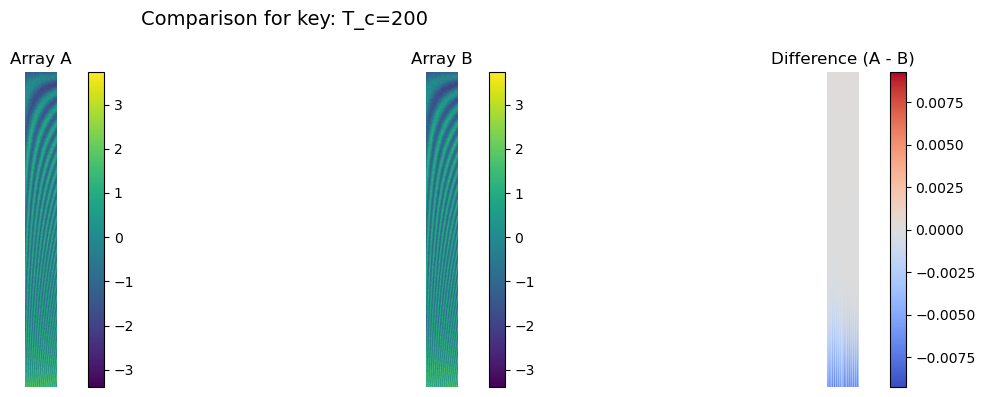

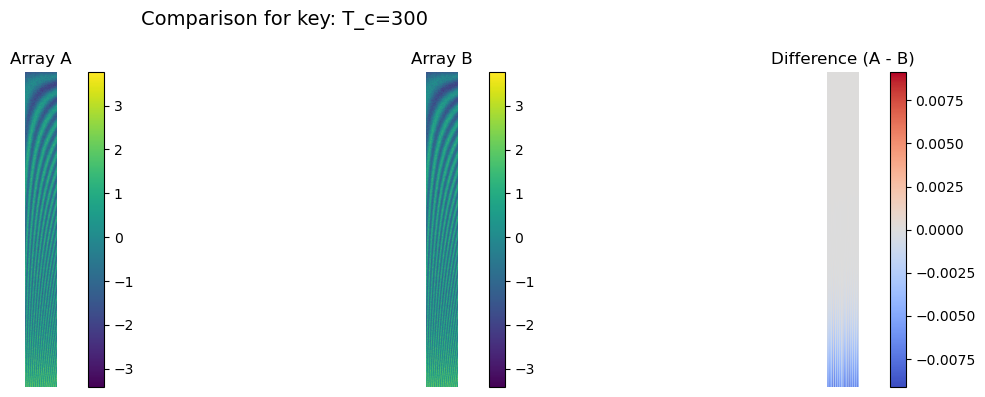

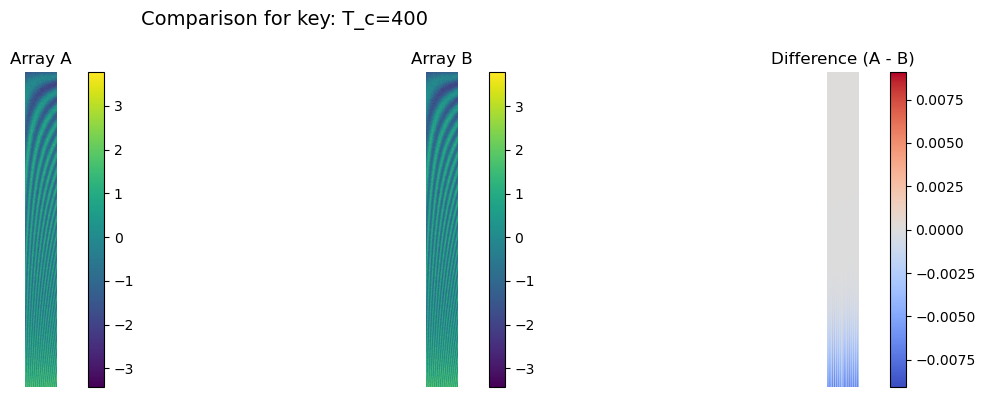

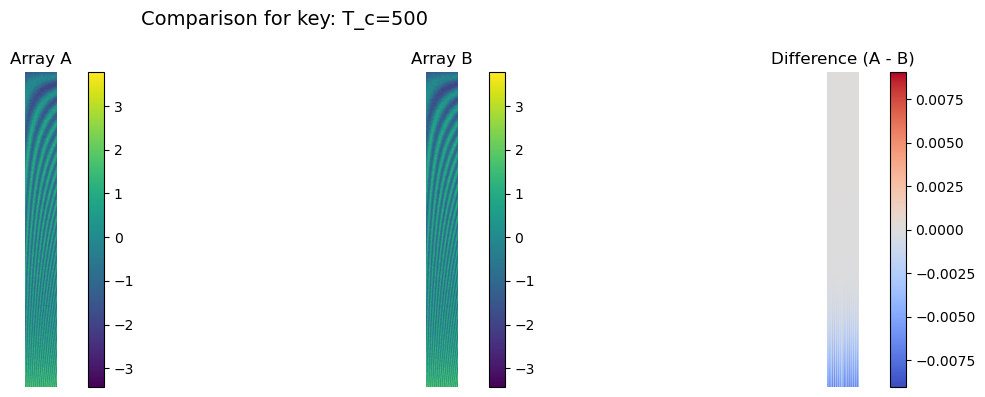

In [82]:
import numpy as np
from matplotlib.colors import TwoSlopeNorm


def visualize_dict_of_arrays(
    dict_a, dict_b, keys=None, cmap="viridis", diff_cmap="coolwarm"
):
    if keys is None:
        keys = dict_a.keys()

    for key in keys:
        arr_a = dict_a[key]
        arr_b = dict_b[key]

        if arr_a.shape != arr_b.shape:
            print(f"Shape mismatch for key '{key}': {arr_a.shape} vs {arr_b.shape}")
            continue

        diff = arr_a - arr_b

        fig, axs = plt.subplots(1, 3, figsize=(15, 4))
        fig.suptitle(f"Comparison for key: {key}", fontsize=14)

        # Regular colormaps for arr_a and arr_b
        im0 = axs[0].imshow(arr_a, cmap=cmap)
        axs[0].set_title("Array A")
        plt.colorbar(im0, ax=axs[0])

        im1 = axs[1].imshow(arr_b, cmap=cmap)
        axs[1].set_title("Array B")
        plt.colorbar(im1, ax=axs[1])

        # Center colormap for the difference plot at zero
        max_diff = np.max(np.abs(diff))
        norm = TwoSlopeNorm(vmin=-max_diff, vcenter=0, vmax=max_diff)
        im2 = axs[2].imshow(diff, cmap=diff_cmap, norm=norm)
        axs[2].set_title("Difference (A - B)")
        plt.colorbar(im2, ax=axs[2])

        for ax in axs:
            ax.axis("off")

        plt.tight_layout()
        plt.show()


visualize_dict_of_arrays(pyboat_outputs, outputs_custom_impl)

In [83]:
import numpy as np


def compare_dicts_of_arrays(a, b, rtol=1e-4, atol=1e-2):
    mismatches = {}
    keys_a = set(a)
    keys_b = set(b)

    if keys_a != keys_b:
        raise ValueError(f"Dict keys do not match: {keys_a ^ keys_b}")

    for key in a:
        arr_a, arr_b = a[key], b[key]
        if not np.allclose(arr_a, arr_b, rtol=rtol, atol=atol):
            diff = np.abs(arr_a - arr_b)
            mismatches[key] = {
                "max_diff": diff.max(),
                "mean_diff": diff.mean(),
                "shape": arr_a.shape,
                "mismatched_elements": np.sum(
                    ~np.isclose(arr_a, arr_b, rtol=rtol, atol=atol)
                ),
            }

    return mismatches  # empty dict if all match


diffs = compare_dicts_of_arrays(pyboat_outputs, outputs_custom_impl)

if not diffs:
    print("All arrays match within tolerance.")
else:
    for k, v in diffs.items():
        print(f"Mismatch in {k}: {v}")

All arrays match within tolerance.
